In [5]:
import pandas as pd

pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 100)

# keep_default_na=False stops pandas from turning the text "None" into NaN
df = pd.read_csv('diabetic_data.csv', keep_default_na=False)

print('Shape:', df.shape)
print(df.dtypes.value_counts())

info = pd.DataFrame({
    'dtype':    df.dtypes.astype(str),
    'n_unique': df.nunique(),
    'example':  df.iloc[0]
})
print(info.to_string())

Shape: (101766, 50)
str      37
int64    13
Name: count, dtype: int64
                          dtype  n_unique                   example
encounter_id              int64    101766                   2278392
patient_nbr               int64     71518                   8222157
race                        str         6                 Caucasian
gender                      str         3                    Female
age                         str        10                    [0-10)
weight                      str        10                         ?
admission_type_id         int64         8                         6
discharge_disposition_id  int64        26                        25
admission_source_id       int64        17                         1
time_in_hospital          int64        14                         1
payer_code                  str        18                         ?
medical_specialty           str        73  Pediatrics-Endocrinology
num_lab_procedures        int64       118     

In [6]:
# STEP 2: Missing values (hidden as '?')
miss = (df == '?').sum()
miss_df = pd.DataFrame({'missing_n': miss,
                        'missing_%': (miss / len(df) * 100).round(2)})
print(miss_df[miss_df.missing_n > 0].sort_values('missing_n', ascending=False))
print('isnull total:', df.isnull().sum().sum(), '| ? total:', miss.sum())
print('Glucose not tested %:', round((df.max_glu_serum == 'None').mean() * 100, 1))
print('A1C not tested %:', round((df.A1Cresult == 'None').mean() * 100, 1))

                   missing_n  missing_%
weight                 98569      96.86
medical_specialty      49949      49.08
payer_code             40256      39.56
race                    2273       2.23
diag_3                  1423       1.40
diag_2                   358       0.35
diag_1                    21       0.02
isnull total: 0 | ? total: 192849
Glucose not tested %: 94.7
A1C not tested %: 83.3


In [7]:
# STEP 3: Duplicates
print('Exact duplicate rows:', df.duplicated().sum())
print('Duplicate encounter_id:', df.encounter_id.duplicated().sum())
vc = df.patient_nbr.value_counts()
print('Unique patients:', df.patient_nbr.nunique())
print('Repeat-patient rows:', df.patient_nbr.duplicated().sum())
print('Patients with >1 visit:', (vc > 1).sum(), '| Max visits:', vc.max())


Exact duplicate rows: 0
Duplicate encounter_id: 0
Unique patients: 71518
Repeat-patient rows: 30248
Patients with >1 visit: 16773 | Max visits: 40


In [8]:
# STEP 4: Inconsistent / invalid values
print(df.gender.value_counts())
print(df.race.value_counts())
print('Expired/hospice:', df.discharge_disposition_id.isin([11,13,14,19,20,21]).sum())
print('Admission type NULL codes:', df.admission_type_id.isin([5,6,8]).sum())
print('Discharge NULL codes:', df.discharge_disposition_id.isin([18,25,26]).sum())
print('Admission source NULL codes:', df.admission_source_id.isin([9,15,17,20,21]).sum())

meds = ['metformin','repaglinide','nateglinide','chlorpropamide','glimepiride',
        'acetohexamide','glipizide','glyburide','tolbutamide','pioglitazone',
        'rosiglitazone','acarbose','miglitol','troglitazone','tolazamide','examide',
        'citoglipton','insulin','glyburide-metformin','glipizide-metformin',
        'glimepiride-pioglitazone','metformin-rosiglitazone','metformin-pioglitazone']
print((df[meds] != 'No').sum().sort_values().head(12))

gender
Female             54708
Male               47055
Unknown/Invalid        3
Name: count, dtype: int64
race
Caucasian          76099
AfricanAmerican    19210
?                   2273
Hispanic            2037
Other               1506
Asian                641
Name: count, dtype: int64
Expired/hospice: 2423
Admission type NULL codes: 10396
Discharge NULL codes: 4680
Admission source NULL codes: 7067
examide                      0
citoglipton                  0
glimepiride-pioglitazone     1
acetohexamide                1
metformin-pioglitazone       1
metformin-rosiglitazone      2
troglitazone                 3
glipizide-metformin         13
tolbutamide                 23
miglitol                    38
tolazamide                  39
chlorpropamide              86
dtype: int64


                  col  min  median  max  lower  upper  n_outliers     %
0    time_in_hospital    1     4.0   14   -4.0   12.0        2252   2.2
1  num_lab_procedures    1    44.0  132   -8.0   96.0         143   0.1
2      num_procedures    0     1.0    6   -3.0    5.0        4954   4.9
3     num_medications    1    15.0   81   -5.0   35.0        2557   2.5
4   number_outpatient    0     0.0   42    0.0    0.0       16739  16.4
5    number_emergency    0     0.0   76    0.0    0.0       11383  11.2
6    number_inpatient    0     0.0   21   -1.5    2.5        7049   6.9
7    number_diagnoses    1     8.0   16    1.5   13.5         281   0.3


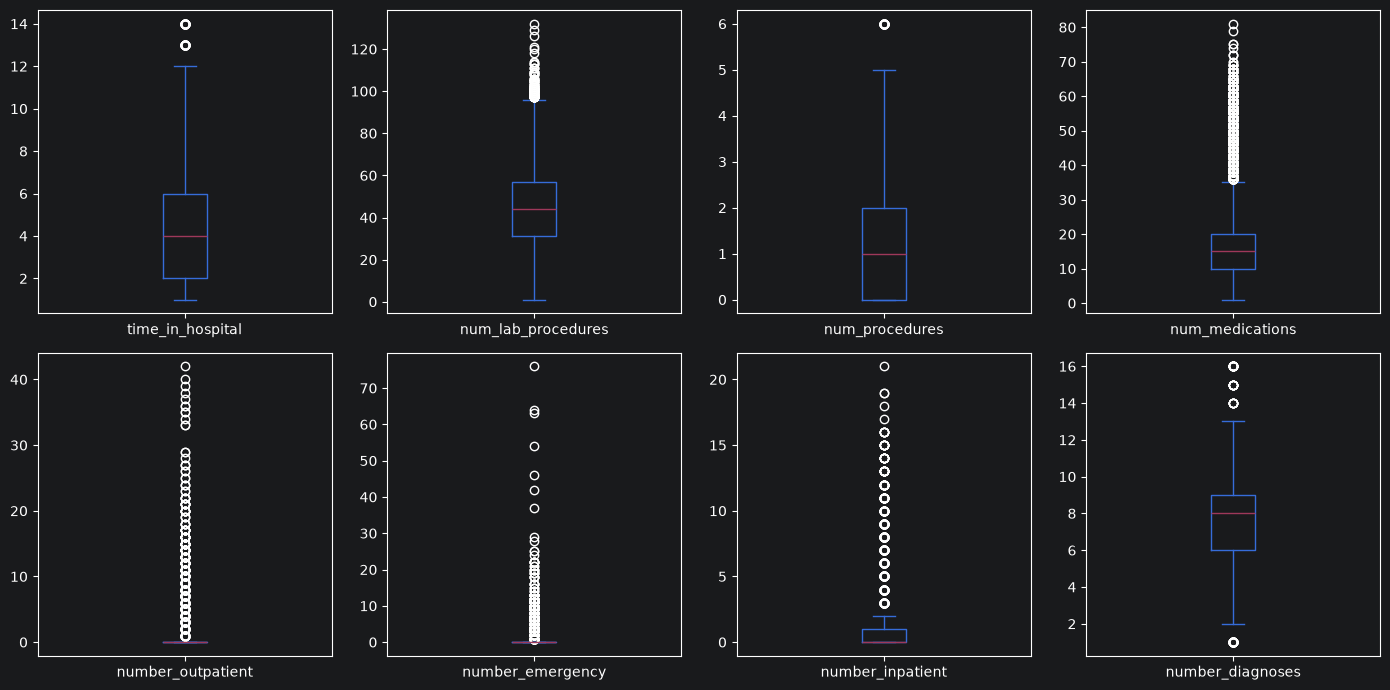

In [9]:
# STEP 5: Outliers (IQR rule)
num = ['time_in_hospital','num_lab_procedures','num_procedures','num_medications',
       'number_outpatient','number_emergency','number_inpatient','number_diagnoses']
rows = []
for c in num:
    s = df[c]
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = int(((s < lo) | (s > hi)).sum())
    rows.append([c, s.min(), s.median(), s.max(), lo, hi, n, round(n/len(s)*100, 1)])
print(pd.DataFrame(rows, columns=['col','min','median','max','lower','upper','n_outliers','%']))

# Optional: boxplots as visual evidence
import matplotlib.pyplot as plt
df[num].plot(kind='box', subplots=True, layout=(2,4), figsize=(14,7), sharex=False, sharey=False)
plt.tight_layout(); plt.show()


In [10]:
# Cell 1: reading and dropping columns/rows
df = pd.read_csv('diabetic_data.csv', keep_default_na=False, dtype=str)
df = df.drop(columns=['weight', 'payer_code'])

drop = [m for m in meds if (df[m] != 'No').sum() < 0.001 * len(df)]
df = df.drop(columns=drop)                                   # 12 drug columns

df = df[df.gender != 'Unknown/Invalid']
df = df[df.diag_1 != '?']
df = df[~df.discharge_disposition_id.isin(['11','13','14','19','20','21'])]


In [11]:
# Cell 2: fixing missing and unclear values
df['race'] = df.race.replace('?', 'Unknown')
df['medical_specialty'] = df.medical_specialty.replace('?', 'Unknown')
vc = df.medical_specialty.value_counts()
rare = vc[vc < 0.01 * len(df)].index
df['medical_specialty'] = df.medical_specialty.replace(dict.fromkeys(rare, 'Other'))

df['diag_2'] = df.diag_2.replace('?', 'None')
df['diag_3'] = df.diag_3.replace('?', 'None')
df['max_glu_serum'] = df.max_glu_serum.replace('None', 'Not tested')
df['A1Cresult'] = df.A1Cresult.replace('None', 'Not tested')

for c, codes in {'admission_type_id': ['5','6','8'],
                 'discharge_disposition_id': ['18','25','26'],
                 'admission_source_id': ['9','15','17','20','21']}.items():
    df[c] = df[c].replace(dict.fromkeys(codes, 'Unknown'))

In [12]:
# Cell 3: data types, diagnosis groups, capped copies, target
age_order = ['[0-10)','[10-20)','[20-30)','[30-40)','[40-50)','[50-60)',
             '[60-70)','[70-80)','[80-90)','[90-100)']
df['age'] = pd.Categorical(df.age, categories=age_order, ordered=True)
df['age_mid'] = df.age.cat.codes * 10 + 5

num = ['time_in_hospital','num_lab_procedures','num_procedures','num_medications',
       'number_outpatient','number_emergency','number_inpatient','number_diagnoses']
df[num] = df[num].astype(int)

def icd9_group(code):
    if code == 'None': return 'None'
    if code[0] in 'VE': return 'Other'
    v = float(code)
    if 390 <= v <= 459 or v == 785: return 'Circulatory'
    if 460 <= v <= 519 or v == 786: return 'Respiratory'
    if 520 <= v <= 579 or v == 787: return 'Digestive'
    if 250 <= v < 251: return 'Diabetes'
    if 800 <= v <= 999: return 'Injury'
    if 710 <= v <= 739: return 'Musculoskeletal'
    if 580 <= v <= 629 or v == 788: return 'Genitourinary'
    if 140 <= v <= 239: return 'Neoplasms'
    return 'Other'

for i in (1, 2, 3):
    df[f'diag_{i}_group'] = df[f'diag_{i}'].map(icd9_group)

for c in num:
    df[c + '_capped'] = df[c].clip(upper=df[c].quantile(.99))

df['readmit_30d'] = (df.readmitted == '<30').astype(int)

In [13]:
# Cell 4: one visit per patient
df = (df.sort_values('encounter_id', key=lambda s: s.astype(int))
        .drop_duplicates('patient_nbr', keep='first'))

In [18]:
df.to_csv('diabetic_data_cleaned_v2.csv', index=False)
raw   = pd.read_csv('diabetic_data.csv', keep_default_na=False, dtype=str)
clean = pd.read_csv('diabetic_data_cleaned_v2.csv', keep_default_na=False, dtype=str)

In [19]:
dead = ['11', '13', '14', '19', '20', '21']

checks = {
    'Rows':                         (len(raw), len(clean)),
    'Columns':                      (raw.shape[1], clean.shape[1]),
    "Cells with '?'":               ((raw == '?').sum().sum(), (clean == '?').sum().sum()),
    "Columns containing '?'":       (((raw == '?').sum() > 0).sum(), ((clean == '?').sum() > 0).sum()),
    'Exact duplicate rows':         (raw.duplicated().sum(), clean.duplicated().sum()),
    'Repeat patient rows':          (raw.patient_nbr.duplicated().sum(), clean.patient_nbr.duplicated().sum()),
    'Invalid gender rows':          ((raw.gender == 'Unknown/Invalid').sum(), (clean.gender == 'Unknown/Invalid').sum()),
    'Expired/hospice rows':         (raw.discharge_disposition_id.isin(dead).sum(), clean.discharge_disposition_id.isin(dead).sum()),
    'Constant columns':             (sum(raw[c].nunique() == 1 for c in raw), sum(clean[c].nunique() == 1 for c in clean)),
    'Specialty categories':         (raw.medical_specialty.nunique(), clean.medical_specialty.nunique()),
}
evidence = pd.DataFrame(checks, index=['Before', 'After']).T
print(evidence)

                        Before  After
Rows                    101766  69979
Columns                     50     49
Cells with '?'          192849      0
Columns containing '?'       7      0
Exact duplicate rows         0      0
Repeat patient rows      30248      0
Invalid gender rows          3      0
Expired/hospice rows      2423      0
Constant columns             2      0
Specialty categories        73     11


In [20]:
n = len(df)   # df = your cleaned data (69,979 rows)

# 1. Class balance
print(df.readmitted.value_counts())
print('30-day rate %:', round(df.readmit_30d.mean() * 100, 2))

# 2. Columns still full of "Unknown / Not tested"
for col, val in [('medical_specialty', 'Unknown'), ('race', 'Unknown'),
                 ('max_glu_serum', 'Not tested'), ('A1Cresult', 'Not tested'),
                 ('admission_type_id', 'Unknown'), ('admission_source_id', 'Unknown')]:
    k = (df[col].astype(str) == val).sum()
    print(col, val, k, round(k / n * 100, 1))

# 3. Skewed count columns
num = ['time_in_hospital','num_lab_procedures','num_procedures','num_medications',
       'number_outpatient','number_emergency','number_inpatient','number_diagnoses']
print(df[num].skew().round(2))
print('Share of zeros %:', {c: round((df[c] == 0).mean() * 100, 1)
      for c in ['number_outpatient', 'number_emergency', 'number_inpatient']})

# 4. Correlations (features with each other, and with the target)
cm = df[num + ['age_mid', 'readmit_30d']].corr().round(2)
print(cm['readmit_30d'].drop('readmit_30d'))
print(cm.loc[['time_in_hospital', 'num_procedures'], ['num_lab_procedures', 'num_medications']])

# 5. Is the 'change' flag consistent with the drug columns? (use the raw data)
ud = raw[meds].isin(['Up', 'Down']).any(axis=1)
print('change=No but Up/Down present:', ((raw.change == 'No') & ud).sum())
print('change=Ch but no Up/Down:', ((raw.change == 'Ch') & ~ud).sum())

readmitted
NO     41472
>30    22224
<30     6283
Name: count, dtype: int64
30-day rate %: 8.98
medical_specialty Unknown 33649 48.1
race Unknown 1916 2.7
max_glu_serum Not tested 66630 95.2
A1Cresult Not tested 57136 81.6
admission_type_id Unknown 7892 11.3
admission_source_id Unknown 5069 7.2
time_in_hospital       1.18
num_lab_procedures    -0.22
num_procedures         1.23
num_medications        1.43
number_outpatient      9.70
number_emergency      21.23
number_inpatient       5.59
number_diagnoses      -0.73
dtype: float64
Share of zeros %: {'number_outpatient': np.float64(87.0), 'number_emergency': np.float64(92.7), 'number_inpatient': np.float64(88.3)}
time_in_hospital      0.06
num_lab_procedures    0.03
num_procedures       -0.00
num_medications       0.04
number_outpatient     0.01
number_emergency      0.03
number_inpatient      0.10
number_diagnoses      0.05
age_mid               0.05
Name: readmit_30d, dtype: float64
                  num_lab_procedures  num_medications


In [23]:
df.to_csv('diabetic_data_cleaned_v2.csv', index=False)